In [5]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, concat, count, lit, row_number, to_timestamp
from pyspark.sql.window import Window
import matplotlib.pyplot as plt

spark = (
    SparkSession.builder
    .appName("weather-visualisation")
    .master("spark://spark-master:7077")
    .getOrCreate()
)

df = (
    spark.read.json("hdfs://namenode:9000/hdfs-data/*/*/alerts.json")
    .withColumn("event_time", to_timestamp("event_time"))
    .dropna(subset=["temperature", "windspeed", "country", "weather_code"])
    .withColumn("ville", concat(col("city"), lit(" ("), col("country"), lit(")")))
)

df.orderBy("event_time").show(5, truncate=False)

+-------+--------------------+-----------------------+----------------+-----------+------------+----------------+---------+----------------------------+
|city   |country             |event_time             |heat_alert_level|temperature|weather_code|wind_alert_level|windspeed|ville                       |
+-------+--------------------+-----------------------+----------------+-----------+------------+----------------+---------+----------------------------+
|Paris  |France              |2026-11-10 15:12:59.738|level_0         |12.5       |3           |level_0         |2.05     |Paris (France)              |
|Paris  |France              |2026-11-10 15:12:59.738|level_0         |12.5       |3           |level_0         |2.05     |Paris (France)              |
|Seville|Spain               |2026-11-10 15:13:00.016|level_0         |21.2       |80          |level_0         |5.24     |Seville (Spain)             |
|Seville|Spain               |2026-11-10 15:13:00.016|level_0         |21.2       

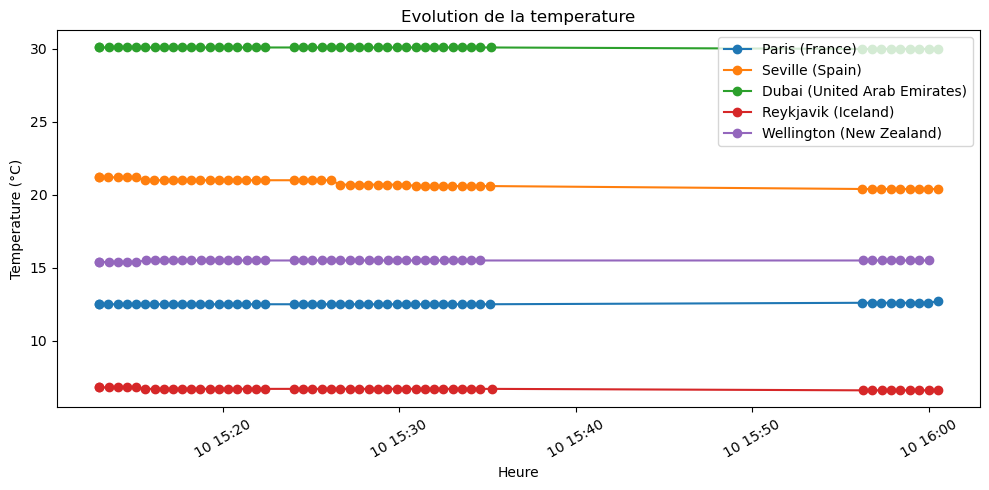

In [10]:
lignes = df.orderBy("event_time").select("event_time", "temperature", "windspeed", "ville").collect()

series = {}
for ligne in lignes:
    serie = series.setdefault(ligne["ville"], {"temps": [], "temperature": [], "vent": []})
    serie["temps"].append(ligne["event_time"])
    serie["temperature"].append(ligne["temperature"])
    serie["vent"].append(ligne["windspeed"])

plt.figure(figsize=(10, 5))
for ville, serie in series.items():
    plt.plot(serie["temps"], serie["temperature"], marker="o", label=ville)
plt.title("Evolution de la temperature")
plt.xlabel("Heure")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

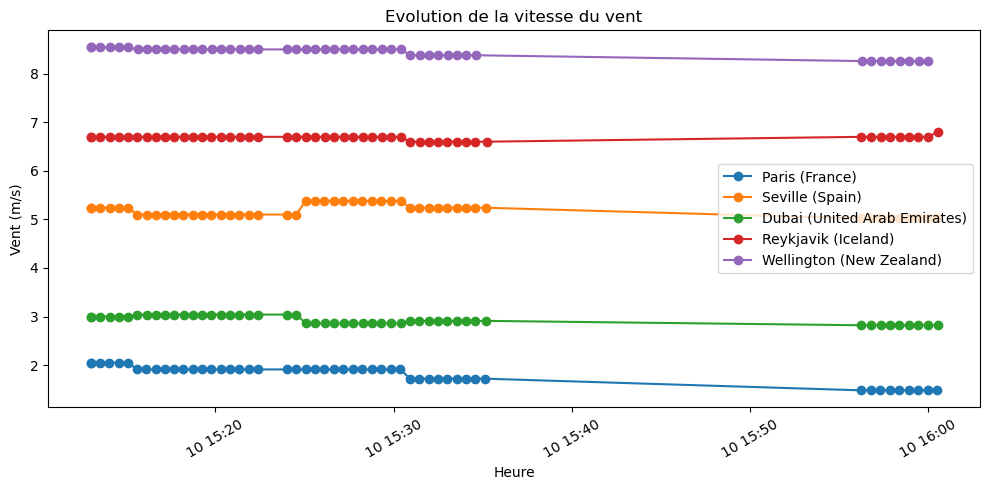

In [11]:
plt.figure(figsize=(10, 5))
for ville, serie in series.items():
    plt.plot(serie["temps"], serie["vent"], marker="o", label=ville)
plt.title("Evolution de la vitesse du vent")
plt.xlabel("Heure")
plt.ylabel("Vent (m/s)")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

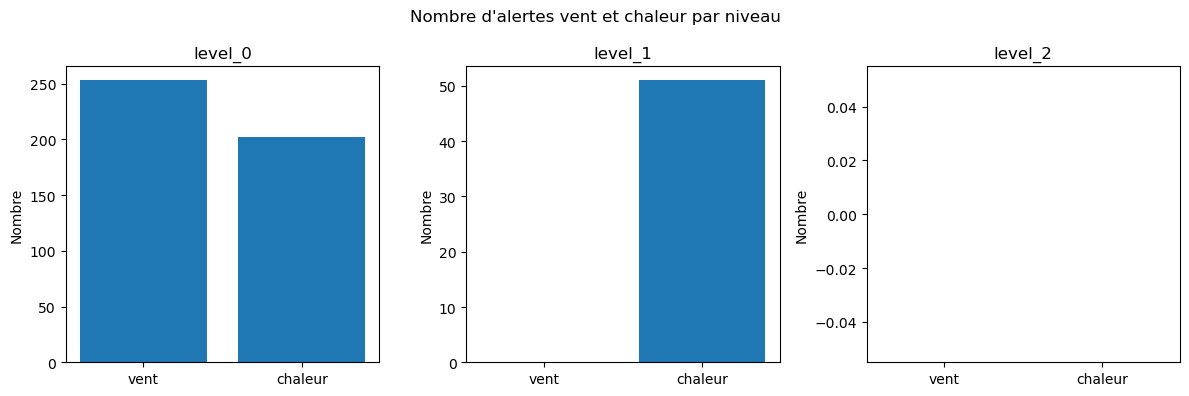

In [13]:
niveaux = ["level_0", "level_1", "level_2"]
vent = {r["wind_alert_level"]: r["count"] for r in df.groupBy("wind_alert_level").count().collect()}
chaleur = {r["heat_alert_level"]: r["count"] for r in df.groupBy("heat_alert_level").count().collect()}

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for axe, niveau in zip(axes, niveaux):
    axe.bar(["vent", "chaleur"], [vent.get(niveau, 0), chaleur.get(niveau, 0)])
    axe.set_title(niveau)
    axe.set_ylabel("Nombre")

fig.suptitle("Nombre d'alertes vent et chaleur par niveau")
plt.tight_layout()
plt.show()

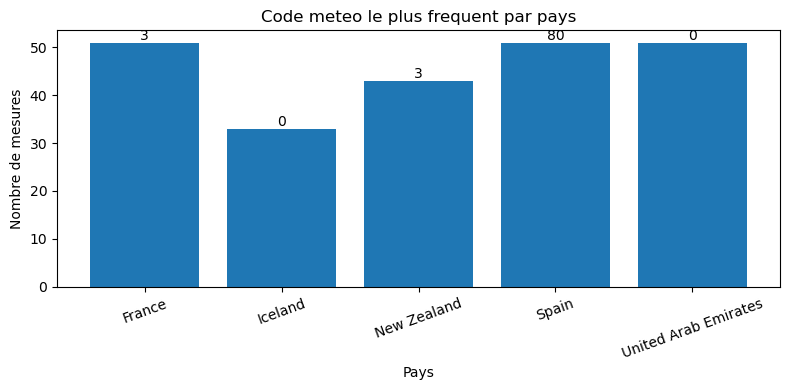

In [14]:
frequence = df.groupBy("country", "weather_code").agg(count("*").alias("nombre"))
fenetre = Window.partitionBy("country").orderBy(col("nombre").desc())
plus_frequent = (
    frequence.withColumn("rang", row_number().over(fenetre))
    .filter(col("rang") == 1)
    .collect()
)

plt.figure(figsize=(8, 4))
barres = plt.bar(
    [r["country"] for r in plus_frequent],
    [r["nombre"] for r in plus_frequent],
)
for barre, ligne in zip(barres, plus_frequent):
    plt.text(barre.get_x() + barre.get_width() / 2, barre.get_height(), int(ligne["weather_code"]), ha="center", va="bottom")
plt.title("Code meteo le plus frequent par pays")
plt.xlabel("Pays")
plt.ylabel("Nombre de mesures")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()